## Motivação  
Quando a distribuição nula pode vir de uma fórmula? E, diante de dados de natureza diferente, qual fórmula usar?  

## Objetivos  

Explicar o que torna um teste paramétrico e o que se ganha e se arrisca com ele.  
Verificar normalidade, homocedasticidade e independência com Q-Q plot, Shapiro-Wilk e o desenho do estudo.  
Escolher o teste pelo objetivo, pela escala da variável e pelo delineamento.  
Aplicar em Python os testes t de uma amostra, de Welch e pareado, a ANOVA, a correlação de Pearson, o teste Z de duas proporções e o 
de independência.  
Interpretar os resultados e reconhecer quando migrar para um teste não paramétrico.

## Preparando os dados

In [2]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid", palette="colorblind")

In [3]:
# Carrega as cinco bases

mtcars = pd.read_csv("../../data/mtcars.csv")
pinguins = pd.read_csv("../../data/penguins.csv")
sonifero = pd.read_csv("../../data/sleep.csv")
iris = pd.read_csv("../../data/iris.csv")
titanic = pd.read_csv("../../data/titanic.csv")

In [4]:
# Resume o resultado de um teste em uma linha legível

def report(name, result, stat="estatística", df=None):
    if isinstance(result, tuple):
        value, p = result
    else:
        value, p = result.statistic, result.pvalue
    df = df if df is not None else getattr(result, "df", None)

    parts = [f"{stat} = {value:.3f}"]
    if df is not None:
        parts.append(f"gl = {df:.4g}" if np.isscalar(df) else f"gl = {df}")
    parts.append("p < 0.001" if p < 0.001 else f"p = {p:.3f}")
    if hasattr(result, "confidence_interval"):
        ci = result.confidence_interval()
        parts.append(f"IC 95% [{ci.low:.2f} ; {ci.high:.2f}]")

    print(f"{name}: " + " · ".join(parts))

## Roteiro:

1. Cenário e Hipóteses: Definir a pergunta, $H_0$ e $H_1$;
2. Premissas: Justifique o teste pela escala/desenho e liste suas premissas;
3. Verificação de Premissas: Cheque normalidade/homocedasticidade/contagens (se passar, execute o teste paramétrico);
4. Execução: Extraia estatística, graus de liberdade, p-valor e IC;
5. Gráfico de Apoio: Plote a visualização que evidencia a diferença ou associação encontrada;
6. Interpretação: Diga se rejeita ou não $H_0$ e responda à pergunta prática do cenário.

### Caso 1 - Gestão de uma frota

1. Cenário e Hipóteses: Definir a pergunta, $H_0$ e $H_1$;

A gestão de uma frota pergunta se o consumo médio (mpg) dos veículos atende à meta de projeto de 20 mpg. Você tem os dados de 32 carros: a média deles basta para responder?

$H_0$: o consumo médio é igual à meta (u=20).  
$H_1$: o consumo médio é diferente da meta (u!=20).

2. Premissas: Justifique o teste pela escala/desenho e liste suas premissas;

In [7]:
mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


In [8]:
print(mtcars[["mpg"]].head())
print("Total de linhas:", len(mtcars))
print("Nulos em mpg:", mtcars["mpg"].isna().sum())

    mpg
0  21.0
1  21.0
2  22.8
3  21.4
4  18.7
Total de linhas: 32
Nulos em mpg: 0


- Escolha do teste: (Qual o objetivo? Qual a escala? Qual o desenho?)

O objetivo é comparar a média de uma única amostra (mpg, variável numérica contínua) com uma meta de referência ($\mu_0 = 20$).  
Teste escolhido é o *t de uma amostra*. 

- Premissas: (Normalidade, Independência, Homocedasticidade)

Observações independentes entre si: Cada linha representa um modelo de carro distinto (32 carros diferentes), sem medições repetidas do mesmo veículo.  
Escala da variável: A variável resposta (mpg) deve ser numérica contínua, permitindo o cálculo válido de média e erro-padrão.   
Distribuição normal na população ou amostra grande o bastante para que a média seja aproximadamente normal, pelo teorema central do limite.  
A premissa de homocedasticidade não se aplica neste caso, pois há apenas um grupo em análise

3. Verificação de Premissas:

Shapiro-Wilk: W = 0.948, p = 0.123


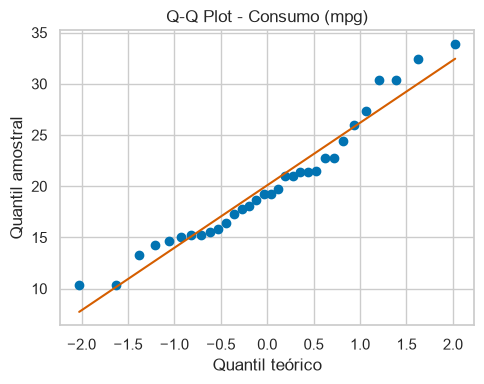

In [11]:
# 1. Teste formal de Shapiro-Wilk (H0: os dados seguem distribuição normal)

w_mpg, p_mpg = stats.shapiro(mtcars["mpg"])
print(f"Shapiro-Wilk: W = {w_mpg:.3f}, p = {p_mpg:.3f}")

mpg = mtcars["mpg"]
fig, ax = plt.subplots(figsize=(5, 4))
stats.probplot(mpg, dist="norm", plot=ax)
ax.set(title="Q-Q Plot - Consumo (mpg)", xlabel="Quantil teórico", ylabel="Quantil amostral")
plt.tight_layout()
plt.show()


O teste de Shapiro-Wilk resulta em $W \approx 0,948$ e $p \approx 0,123$ (como $p > 0,05$) então não rejeitamos a hipótese de normalidade.  
No Q-Q plot, os pontos acompanham a reta diagonal sem desvios severos nas pontas.   
Veredito: As premissas foram atendidas. Podemos seguir com o teste paramétrico (não precisamos migrar para o teste não paramétrico de Wilcoxon).

4. Execução: Extraia estatística, graus de liberdade, p-valor e IC;

In [19]:
# Teste t de uma amostra com o SciPy

# mpg = mtcars["mpg"] etapa anterior
meta = 20

caso1 = stats.ttest_1samp(mpg, popmean=meta)

print(f"Média amostral = {mpg.mean():.2f} mpg")
report("t de uma amostra", caso1, stat="t")

Média amostral = 20.09 mpg
t de uma amostra: t = 0.085 · gl = 31 · p = 0.933 · IC 95% [17.92 ; 22.26]


In [20]:
caso1

TtestResult(statistic=np.float64(0.08506003568133688), pvalue=np.float64(0.932760640909387), df=np.int64(31))

In [21]:
res_caso1 = stats.ttest_1samp(mpg, popmean=meta)
ci = res_caso1.confidence_interval()

print(f"Média amostral = {mpg.mean():.2f} mpg")
print(f"t = {res_caso1.statistic:.3f}, gl = {res_caso1.df}, p = {res_caso1.pvalue:.3f}")
print(f"IC 95% = [{ci.low:.2f}; {ci.high:.2f}]")

Média amostral = 20.09 mpg
t = 0.085, gl = 31, p = 0.933
IC 95% = [17.92; 22.26]


6. Interpretação:  

Obtivemos $t = 0,085$ ($gl = 31$) e $p = 0,933$. Como $p > 0,05$, não rejeitamos $H_0$.  
Além disso, o intervalo de confiança de 95% vai de $17,92$ a $22,26\text{ mpg}$, contendo o valor da meta ($20\text{ mpg}$) com folga.  
Não rejeitamos $H_0$: não há evidência de que a frota esteja fora da meta.  


Resposta de negócio: A média observada na frota ($20,09\text{ mpg}$) está muito próxima da meta e a pequena diferença se deve à variação natural entre os veículos. Portanto, não há evidência estatística de que o consumo médio da frota seja diferente de $20\text{ mpg}$.